# Проект спринта 27. Часть 1: анализ и подготовка данных

Это первая из двух тетрадок, в которых вы будете выполнять проект по извлечению именованных сущностей (NER). Здесь вы познакомитесь с разметкой WikiANN, исследуете русскоязычную часть датасета и подготовите её для BERT: токенизируете предложения и выровняете NER-метки
с подтокенами.

**Датасет:** [WikiANN](https://huggingface.co/datasets/unimelb-nlp/wikiann), русскоязычная
конфигурация. Типы сущностей: `PER`, `ORG`, `LOC`. Схема разметки — IOB2.

**Токенизатор:** `bert-base-multilingual-cased`.

> **Где выполнять:** на своём компьютере — GPU здесь не нужен. Не запускайте виртуальную машину — она понадобится только во второй части проекта.

## Как работать с тетрадкой

Выполняйте ячейки последовательно. Дополняйте ячейки с пометкой `TODO`, сохраняйте
результаты вычислений и записывайте выводы в соответствующих ячейках Markdown.

Структура тетрадки:

- Шаг 1 — подготовка окружения и обеспечение воспроизводимости.
- Шаг 2 — знакомство с данными и EDA.
- Шаг 3 — токенизация и выравнивание меток.
- Написание выводов и самопроверка по чек-листу.

## Шаг 1. Подготовка окружения и обеспечение воспроизводимости

Установите зависимости, импортируйте библиотеки и зафиксируйте `SEED`.

In [1]:
# Установка библиотек
# Установка библиотек
%pip install -q \
    numpy==2.2.6 \
    pandas==3.0.1 \
    matplotlib==3.10.8 \
    torch==2.6.0 \
    transformers==5.14.1 \
    datasets==4.1.1 \
    evaluate==0.4.6 \
    seqeval==1.2.2 \
    spacy==3.8.7 \
    accelerate

Note: you may need to restart the kernel to use updated packages.


In [49]:
from collections import Counter
from importlib.metadata import version

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from seqeval.metrics.sequence_labeling import get_entities
from spacy import displacy
from transformers import (
    AutoTokenizer,
    DataCollatorForTokenClassification,
    set_seed,
)

In [3]:
SEED = 42
set_seed(SEED)

print("Версии: " + ", ".join(
    f"{package}={version(package)}"
    for package in [
        "torch",
        "transformers",
        "datasets",
        "seqeval",
        "spacy",
    ]
))

Версии: torch=2.6.0+cpu, transformers=5.14.1, datasets=4.1.1, seqeval=1.2.2, spacy=3.8.7


## Шаг 2. Знакомство с данными и их анализ

WikiANN построен автоматически на основе статей Википедии. Один пример содержит
исходные `tokens`, числовые `ner_tags` и служебные поля `langs`, `spans`.

В IOB2 каждая новая сущность начинается с `B-*`, её продолжение размечается `I-*`,
а токены вне сущностей — `O`. При подсчёте распределения одна метка `B-*`
соответствует одной сущности.


In [4]:
# Загрузка русскоязычной конфигурации WikiANN
raw_datasets = load_dataset("unimelb-nlp/wikiann", "ru")

print(f"Размер обучающей выборки:   {len(raw_datasets['train'])}")
print(f"Размер валидационной:       {len(raw_datasets['validation'])}")
print(f"Размер тестовой:            {len(raw_datasets['test'])}")

# Получаем метки из структуры датасета
label_list = raw_datasets["train"].features["ner_tags"].feature.names
id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}
ENTITY_TYPES = sorted({
    label.split("-")[-1]
    for label in label_list
    if label != "O"
})

print(f"Метки: {label_list}")
print(f"Типы сущностей: {ENTITY_TYPES}")


Размер обучающей выборки:   20000
Размер валидационной:       10000
Размер тестовой:            10000
Метки: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
Типы сущностей: ['LOC', 'ORG', 'PER']


### Анализ примеров разметки

Выведите первые два примера из обучающей выборки. Покажите исходный текст и пары «токен — строковая метка» для размеченных сущностей.


In [5]:
# TODO: дополните вывод двух примеров
for i in range(2):
    tokens = raw_datasets["train"][i]["tokens"]
    tags = [label_list[tag] for tag in raw_datasets["train"][i]["ner_tags"]]
    # Выведите предложение и токены с метками, отличными от O
    # Ваш код:
    print("Предложение: ",' '.join(tokens))
    for token, tag in zip(tokens, tags):
        if tag != 'O':
            print("Пара: ", token, tag)
    

Предложение:  Илизаров , Гавриил Абрамович
Пара:  Илизаров B-PER
Пара:  , I-PER
Пара:  Гавриил I-PER
Пара:  Абрамович I-PER
Предложение:  ' '' Рыбницкий район '' '
Пара:  Рыбницкий B-LOC
Пара:  район I-LOC


### Демонстрация сущностей

Используйте готовую функцию и выведите три предложения из валидационной выборки, в которых подсвечены размеченные сущности. Проверьте, что многословные сущности отображаются единым фрагментом.


In [6]:
def visualize_ner(example, label_list):
    """Подсвечивает целые IOB2-сущности в одном примере WikiANN."""
    tokens = example["tokens"]
    tags = [label_list[tag] for tag in example["ner_tags"]]
    text = " ".join(tokens)

    offsets = []
    cursor = 0
    for token in tokens:
        offsets.append((cursor, cursor + len(token)))
        cursor += len(token) + 1

    ents = [
        {
            "start": offsets[start][0],
            "end": offsets[end][1],
            "label": entity_type,
        }
        for entity_type, start, end in get_entities(tags)
    ]
    displacy.render(
        {"text": text, "ents": ents},
        style="ent",
        manual=True,
        jupyter=True,
    )


# TODO: вызовите visualize_ner для трёх примеров из валидационной выборки

label_list_val = raw_datasets["validation"].features["ner_tags"].feature.names
for i in range(3):
    visualize_ner(raw_datasets["validation"][i], label_list_val)

### Анализ распределения сущностей

На обучающей выборке посчитайте количество сущностей `PER`, `ORG`, `LOC` по меткам `B-*`,
выведите полученные значения и отобразите их на столбчатой диаграмме. Не считайте `I-*` отдельными сущностями.


Counter({'LOC': 9498, 'ORG': 7944, 'PER': 7187})


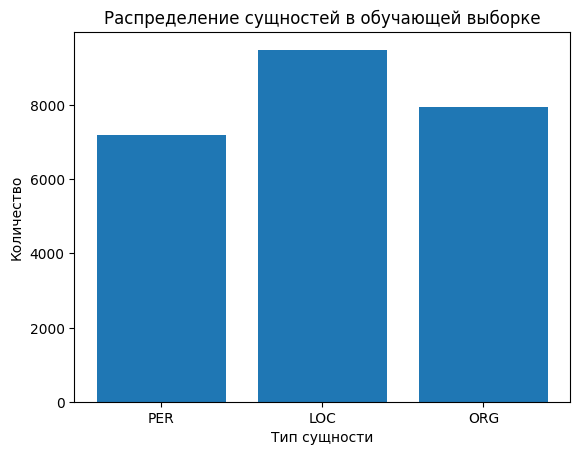

In [7]:
# TODO: сформируйте список типов сущностей по тегам B-*

entity_types = []

for example in raw_datasets["train"]:
    for tag_id in example["ner_tags"]:
        tag = label_list[tag_id]
        if tag.startswith("B-"):
            entity_types.append(tag[2:])

type_counts = Counter(entity_types)
print(type_counts)
# TODO: выведите значения и постройте столбчатую диаграмму

plt.bar(type_counts.keys(), type_counts.values())
plt.xlabel("Тип сущности")
plt.ylabel("Количество")
plt.title("Распределение сущностей в обучающей выборке")
plt.show()

### Изучение длин предложений

Рассчитайте длины предложений в обучающей выборке по числу исходных `tokens`.
Постройте распределение и выведите минимум, максимум и медиану.


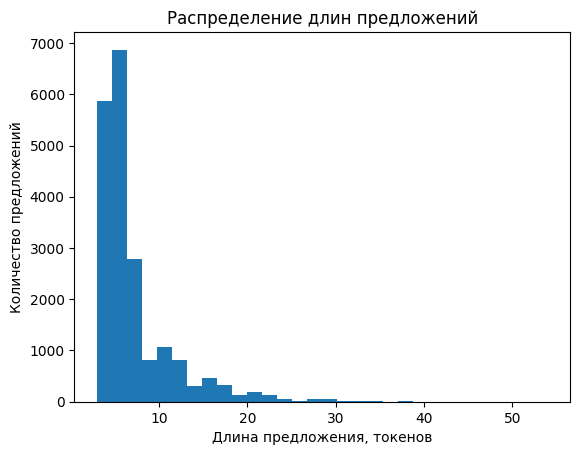

Минимум: 3
Максимум: 54
Медиана: 6.0


In [8]:
# TODO: рассчитайте длины предложений и постройте гистограмму
sentence_lengths = [
    len(examples["tokens"])
    for examples in raw_datasets["train"]
]

plt.hist(sentence_lengths, bins=30)
plt.xlabel("Длина предложения, токенов")
plt.ylabel("Количество предложений")
plt.title("Распределение длин предложений")
plt.show()

# TODO: выведите минимум, максимум и медиану

print("Минимум:", min(sentence_lengths))
print("Максимум:", max(sentence_lengths))
print("Медиана:", np.median(sentence_lengths))

### Выводы

> **TODO:** кратко опишите соотношение типов сущностей, характерные длины предложений и замеченные особенности автоматической разметки WikiANN.

В обучающей выборке наиболее часто встречаются сущности типа `LOC` - 9498, далее `ORG` - 7944 и `PER` - 7187. Дисбаланс между классами есть, но он не выглядит критическим.

Предложения в основном короткие: медианная длина составляет 6 токенов, минимальная - 3, максимальная - 54 токена. Распределение имеет выраженный правый хвост: большинство примеров сосредоточено в области малых длин, а длинные предложения встречаются редко.

При просмотре примеров WikiANN заметны особенности автоматической разметки: границы сущностей не всегда выглядят естественно. Например, пунктуация может быть размечена как часть сущности (`Илизаров , Гавриил Абрамович`). Это следует учитывать при дальнейшем обучении и анализе ошибок модели.


## Шаг 3. Токенизация и выравнивание меток

BERT может разбить одно исходное слово на несколько токенов-подслов. В этом проекте
исходная NER-метка назначается только первому токену. Продолжения слова,
специальные токены и паддинг получают `-100` и исключаются из расчёта функции потерь.


In [18]:
model_checkpoint = "bert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)


In [19]:
def tokenize_and_align_labels(examples):
    """Токенизирует слова и выравнивает NER-метки с подсловами."""
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True,
    )

    labels = []
    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []

        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)
            elif word_idx != previous_word_idx:
                label_ids.append(label[word_idx])
            else:
                label_ids.append(-100)
            previous_word_idx = word_idx

        labels.append(label_ids)

    tokenized_inputs["labels"] = labels
    return tokenized_inputs


### Анализ работы `word_ids()`

С помощью зафиксированного `SEED` выберите два примера из обучающей выборки. Для каждой позиции выведите последовательность значений:

```text
токен → word_id → метка после выравнивания
```

Проверьте специальные токены, первый токен слова и его продолжения.


In [20]:
examples_to_trace = raw_datasets["train"].shuffle(seed=SEED).select(range(2))

for i in range(len(examples_to_trace["tokens"])):
    tokens = examples_to_trace["tokens"][i]
    tags = examples_to_trace["ner_tags"][i]
    tokenized = tokenizer(tokens, is_split_into_words=True)
    word_ids = tokenized.word_ids()
    subtokens = tokenizer.convert_ids_to_tokens(tokenized["input_ids"])

    # TODO: выровняйте метки по тем же правилам, что и в функции выше
    aligned_labels = []
    previous_word_idx = None
    for word_idx in word_ids:
        if word_idx is None:
            aligned_labels.append(-100)
        elif word_idx != previous_word_idx:
            aligned_labels.append(tags[word_idx])
        else:
            aligned_labels.append(-100)
        previous_word_idx = word_idx
    # TODO: выведите токен, word_id и читаемую метку для каждой позиции
    for token, word_id, label in zip(subtokens, word_ids, aligned_labels):
        print(f"token: {token}, word_id: {word_id}, label: {label if label == -100 else label_list[label]}")


token: [CLS], word_id: None, label: -100
token: ', word_id: 0, label: O
token: ', word_id: 1, label: O
token: ', word_id: 1, label: -100
token: Польша, word_id: 2, label: B-LOC
token: ', word_id: 3, label: O
token: ', word_id: 3, label: -100
token: ', word_id: 4, label: O
token: [UNK], word_id: 5, label: O
token: [SEP], word_id: None, label: -100
token: [CLS], word_id: None, label: -100
token: К, word_id: 0, label: O
token: ##арт, word_id: 0, label: -100
token: ##ина, word_id: 0, label: -100
token: была, word_id: 1, label: O
token: при, word_id: 2, label: O
token: ##ве, word_id: 2, label: -100
token: ##зен, word_id: 2, label: -100
token: ##а, word_id: 2, label: -100
token: из, word_id: 3, label: O
token: Ф, word_id: 4, label: B-LOC
token: ##лор, word_id: 4, label: -100
token: ##ен, word_id: 4, label: -100
token: ##ции, word_id: 4, label: -100
token: в, word_id: 5, label: O
token: Мюнхен, word_id: 6, label: B-LOC
token: после, word_id: 7, label: O
token: почти, word_id: 8, label: O
toke

### Почему используется `-100`

> **TODO:** объясните, почему специальные токены и продолжения слова получают `-100`,
> а не класс `O` или копию исходной метки.


Специальные токены вроде [CLS] и [SEP] не относятся ни к одному слову исходного текста, поэтому для задачи NER им не нужна отдельная метка. Продолжения слова после WordPiece-разбиения тоже не размечаются отдельно, потому что исходная метка относится ко всему слову целиком. Поэтому таким позициям присваивается -100, чтобы они не участвовали в расчёте функции потерь. Если вместо этого поставить класс O или скопировать исходную метку, модель будет обучаться на искусственно добавленных метках, которых не было в исходной разметке.

### Применение функции ко всему датасету

Примените `tokenize_and_align_labels` к обучающей, валидационной и тестовой выборкам
с помощью `.map()`. Функция рассчитана на обработку нескольких примеров, поэтому
обязательно укажите `batched=True`. Удалите исходные столбцы через
`remove_columns=raw_datasets["train"].column_names`.


In [26]:
# TODO: примените tokenize_and_align_labels ко всем выборкам

# Подсказка по обязательным аргументам:
tokenized_datasets = raw_datasets.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=raw_datasets["train"].column_names,
)
tokenized_datasets["train"][1]

{'input_ids': [101,
  112,
  112,
  112,
  525,
  10292,
  90284,
  36643,
  14659,
  112,
  112,
  112,
  102],
 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
 'labels': [-100, 0, 0, -100, 5, -100, -100, -100, 6, 0, -100, 0, -100]}

### Проверка выравнивания

Для каждого примера во всех выборках проверьте равенство длин `input_ids`,
`attention_mask`, `labels`. На первых 100 примерах каждой выборки убедитесь, что
`-100` стоит на специальных токенах и продолжениях слов.


In [ ]:
# TODO: проверьте длины для каждого примера во всех трёх выборках
bad_indices_train = [] # список куда будут накапливаться "лишние" индексы при наличии
for i, example in enumerate(tokenized_datasets["train"]):
    if not (len(example["input_ids"])) == (len(example["attention_mask"])) == (len(example["labels"])):
        bad_indices_train.append(i)
print("Список индексов примеров где длины не совпадают у train", bad_indices_train)

bad_indices_validation = [] # список куда будут накапливаться "лишние" индексы val
for i, example in enumerate(tokenized_datasets["validation"]):
    if not (len(example["input_ids"])) == (len(example["attention_mask"])) == (len(example["labels"])):
        bad_indices_validation.append(i)
print("Список индексов примеров где длины не совпадают у validation", bad_indices_validation)

bad_indices_test = [] # список куда будут накапливаться "лишние" индексы test
for i, example in enumerate(tokenized_datasets["test"]):
    if not (len(example["input_ids"])) == (len(example["attention_mask"])) == (len(example["labels"])):
        bad_indices_test.append(i)

print("Список индексов примеров где длины не совпадают у test", bad_indices_test)

# TODO: проверьте позиции -100 на первых 100 примерах каждой выборки
for split in ("train", "validation", "test"):
    has_errors = False
    for i in range(100): # берем первые 100 примеров в конкретной выборке
        raw_example = raw_datasets[split][i]
        tokenized_example = tokenized_datasets[split][i]
        
        tokens = raw_example["tokens"] # токены
        labels = tokenized_example['labels'] # метки
        tokenized = tokenizer(tokens, is_split_into_words=True, truncation=True)
        word_ids = tokenized.word_ids() # индексы слов
        # Далее внутри примера соотносим пары индекс слова-метка
        previous_word_idx = None
        for word_idx, label in zip(word_ids, labels):
            if (word_idx is None or (word_idx == previous_word_idx)) and\
            label != -100:
                print("Ошибка: ", split, i)
                has_errors = True
            previous_word_idx = word_idx
    if not has_errors:
        print(f"В выборке {split} Ошибок не обнаружено")
            
        
        
        

Список индексов примеров где длины не совпадают у train []
Список индексов примеров где длины не совпадают у validation []
Список индексов примеров где длины не совпадают у test []
В выборке train Ошибок не обнаружено
В выборке validation Ошибок не обнаружено
В выборке test Ошибок не обнаружено


### Проверка динамического паддинга

Создайте коллатор и демонстрационный батч из четырёх примеров. Проверьте формы
`input_ids`, `attention_mask`, `labels` и метки на позициях padding.


In [ ]:
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

# TODO: сформируйте батч из четырёх обучающих примеров
batch_4 = [tokenized_datasets["train"][i] for i in range(4)]
batch = data_collator(batch_4)
print(batch["labels"].dtype) # проверка типа меток на батче
# TODO: проверьте равенство форм
if not (batch["input_ids"].shape) == (batch["attention_mask"].shape) == (batch["labels"].shape):
        print("Формы не равны")
else: print("Формы ОК")
# TODO: проверьте attention_mask == 0 и labels == -100 на padding
padding_mask = batch["attention_mask"] == 0
pad_positions = batch["labels"][padding_mask]
print(torch.all(pad_positions == -100))


torch.int64
Формы ОК
tensor(True)


### Вывод

> **TODO:** подтвердите результатами проверок, что все три выборки готовы к подаче в модель. Укажите назначение `word_ids()` и `-100`.


### Вывод

Проверки показали, что обучающая, валидационная и тестовая выборки готовы к подаче в модель. Для каждого примера длины `input_ids`, `attention_mask` и `labels` совпадают. На первых 100 примерах каждой выборки подтверждено, что специальные токены и продолжения слов получают метку `-100`. Также проверен динамический padding: после формирования батча формы всех трёх тензоров совпадают, а на padding-позициях `attention_mask = 0` и `labels = -100`.

Метод `word_ids()` используется для связи токенов, полученных после токенизации, с исходными словами. Это необходимо, чтобы правильно перенести NER-метки после WordPiece-разбиения слова на несколько подтокенов - subtokens.

Значение `-100` обозначает позиции, которые не должны участвовать в расчёте функции потерь. Оно используется для специальных токенов, продолжений слова после первого subtoken и padding-позиций.

## Что дальше

Подготовка данных завершена. Вторая часть проекта посвящена обучению моделей и анализу ошибок, её нужно выполнять на виртуальной машине с GPU.

Переносить подготовленные данные на VM не требуется: во второй тетрадке есть код для загрузки и подготовки данных без пропущенных ячеек. Разбираться в нём заново
не нужно — вы уже сделали это здесь.

Прежде чем инициализировать VM, убедитесь, что чек-лист ниже выполнен полностью:
исправлять подготовку данных, расходуя ограниченное время работы с GPU, невыгодно.

## Ресурсы

- [WikiANN](https://huggingface.co/datasets/unimelb-nlp/wikiann)
- [Hugging Face Datasets](https://huggingface.co/docs/datasets/)
- [Hugging Face: Token Classification](https://huggingface.co/docs/transformers/tasks/token_classification)
- [bert-base-multilingual-cased](https://huggingface.co/bert-base-multilingual-cased)

## Чек-лист готовности первой части проекта

### Анализ данных

- [-] Выведены размеры выборок, список меток и типы сущностей.
- [-] Показаны два примера именованных сущностей с читаемой разметкой.
- [-] Продемонстрировано минимум три предложения с подсвеченными именованными сущностями.
- [-] Построено распределение типов сущностей и сделан вывод о дисбалансе.
- [-] Построено распределение длин предложений, выведены минимум, максимум и медиана.

### Токенизация и выравнивание

- [-] Разобрана работа `word_ids()` на двух примерах.
- [-] Подготовлены обучающая, валидационная и тестовая выборки.
- [-] Для всех примеров совпадают длины `input_ids`, `attention_mask`, `labels`.
- [-] `-100` стоит на специальных токенах, паддинге и продолжениях слов.
- [-] Объяснено назначение `-100`.
- [-] Проверен целочисленный `dtype` поля `labels` в батче.

### Перед переходом ко второй тетрадке

- [-] Во всех случайных операциях используется единый `SEED`.
- [-] Все обязательные `TODO` заполнены, временные заглушки удалены.
- [-] Ядро перезапущено, тетрадка выполнена сверху вниз без ошибок.
- [-] Результаты вычислений и визуализации сохранены в тетрадке.